# CR05 - Score drift monitoring (LendingClub)

Goal: decide when the score population has drifted enough to retrain. The CR02 monotone
LightGBM challenger is fit on loans issued 2007 to 2014. Its score distribution on 2015 to 2016
loans is compared month by month with a reference (training scores). We track PSI, KS, and Gini
per month, and flag months with PSI above 0.25.

Data: LendingClub accepted loans (Kaggle), resolved outcomes only, same split as CR02.
Target: good = Fully Paid. Test window ends 2016-12 (2017 and 2018 outcomes are censored).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from credit_core.metrics import gini
from gbm_monotone.pipeline import challenger_scores, fit_challenger, load_oot
from score_drift.monitor import PSI_RETRAIN, first_alert, monthly_drift, retrain_flags

FIG = Path("../reports/figures")
FIG.mkdir(parents=True, exist_ok=True)
RNG = np.random.default_rng(42)

## 1. Fit the challenger on 2007 to 2014 and score the reference

In [2]:
d = load_oot()
model = fit_challenger(d)
print(f"Train n = {len(d.y_train):,}, test n = {len(d.y_test):,}")

ref_idx = RNG.choice(len(d.X_train), size=min(200_000, len(d.X_train)), replace=False)
reference = challenger_scores(model, d, d.X_train.iloc[ref_idx])
score_test = challenger_scores(model, d, d.X_test)

overall_gini = gini(d.y_test, score_test)
print(f"Overall test Gini (2015 to 2016): {overall_gini:.3f}")

Train n = 453,809, test n = 668,651


Overall test Gini (2015 to 2016): 0.430


## 2. Monthly monitoring table

In [3]:
table = retrain_flags(
    monthly_drift(d.issue_test, d.y_test, score_test, reference, min_n=5000),
    threshold=PSI_RETRAIN,
)
table.round(4)

,n,bad_rate,mean_score,psi,ks,gini,psi_alert
month,,,,,,,
2015-01,32216,0.2005,0.8198,0.0067,0.3146,0.4344,False
2015-02,21656,0.1938,0.8223,0.0042,0.3264,0.4417,False
2015-03,22931,0.2084,0.8204,0.0073,0.3270,0.4353,False
2015-04,31785,0.2048,0.8231,0.0034,0.3131,0.4305,False
2015-05,28711,0.2049,0.8231,0.0041,0.3141,0.4406,False
2015-06,25446,0.2080,0.8237,0.0045,0.3358,0.4566,False
2015-07,41053,0.2022,0.8261,0.0029,0.3346,0.4603,False
2015-08,31701,0.2000,0.8279,0.0031,0.3519,0.4768,False
2015-09,25150,0.2060,0.8274,0.0029,0.3342,0.4626,False


In [4]:
print(f"First month above PSI {PSI_RETRAIN}: {first_alert(table)}")
print(f"Months flagged: {int(table['psi_alert'].sum())} of {len(table)}")

First month above PSI 0.25: None
Months flagged: 0 of 24


## 3. Plots

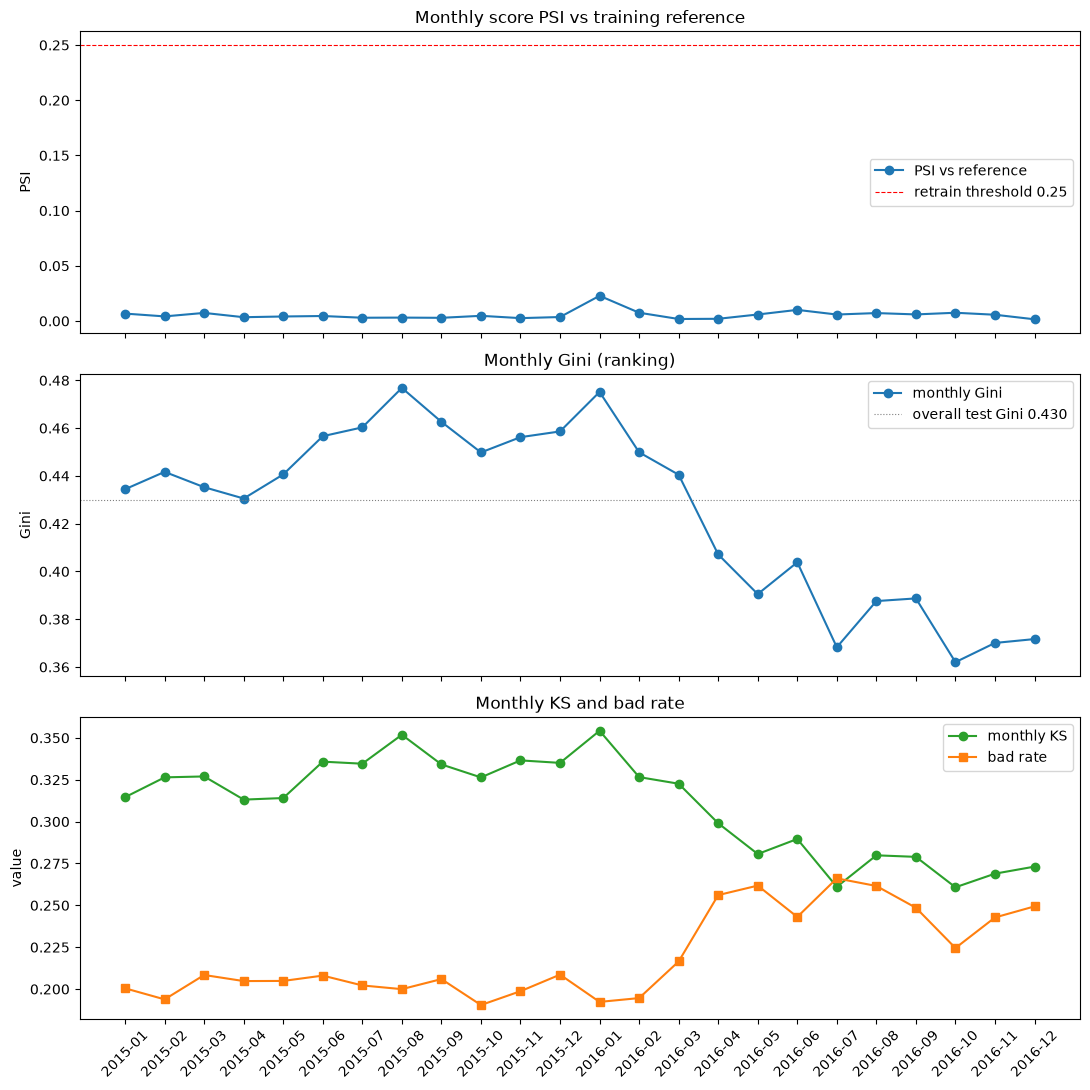

In [5]:
fig, axes = plt.subplots(3, 1, figsize=(11, 11), sharex=True)
x = table.index

axes[0].plot(x, table["psi"], marker="o", label="PSI vs reference")
axes[0].axhline(PSI_RETRAIN, color="red", ls="--", lw=0.8, label=f"retrain threshold {PSI_RETRAIN}")
axes[0].set(ylabel="PSI", title="Monthly score PSI vs training reference")
axes[0].legend()

axes[1].plot(x, table["gini"], marker="o", label="monthly Gini")
axes[1].axhline(overall_gini, color="gray", ls=":", lw=0.8, label=f"overall test Gini {overall_gini:.3f}")
axes[1].set(ylabel="Gini", title="Monthly Gini (ranking)")
axes[1].legend()

axes[2].plot(x, table["ks"], marker="o", color="tab:green", label="monthly KS")
axes[2].plot(x, table["bad_rate"], marker="s", color="tab:orange", label="bad rate")
axes[2].set(ylabel="value", title="Monthly KS and bad rate")
axes[2].tick_params(axis="x", rotation=45)
axes[2].legend()

fig.tight_layout()
fig.savefig(FIG / "cr05_monthly_monitoring.png", dpi=120)
plt.show()

## 4. Summary

- PSI stays below 0.03 in every month (no retrain trigger). The input score distribution has
  not moved, so PSI alone would say the model is fine.
- Monthly Gini falls from 0.43 to 0.48 in 2015 to 0.36 to 0.37 in late 2016. The bad rate
  rises from about 0.19 to 0.21 in 2015 to about 0.25 to 0.27 in mid and late 2016, while the mean
  score barely changes. This is performance drift, which PSI does not detect. Gini and bad-rate
  monitoring must be tracked alongside PSI.
- Caveat: the late-2016 drop is partly a resolved-only effect. Loans issued in late 2016 that
  have a final status are mostly fast resolutions (early payoffs or defaults), not a random
  sample. The drop may be part selection bias, and it cannot be separated from real drift here.
- Months with fewer than 5,000 loans get no PSI, and months with one outcome class get no
  Gini or KS.

In [6]:
table.round(3)

,n,bad_rate,mean_score,psi,ks,gini,psi_alert
month,,,,,,,
2015-01,32216,0.200,0.820,0.007,0.315,0.434,False
2015-02,21656,0.194,0.822,0.004,0.326,0.442,False
2015-03,22931,0.208,0.820,0.007,0.327,0.435,False
2015-04,31785,0.205,0.823,0.003,0.313,0.431,False
2015-05,28711,0.205,0.823,0.004,0.314,0.441,False
2015-06,25446,0.208,0.824,0.005,0.336,0.457,False
2015-07,41053,0.202,0.826,0.003,0.335,0.460,False
2015-08,31701,0.200,0.828,0.003,0.352,0.477,False
2015-09,25150,0.206,0.827,0.003,0.334,0.463,False
